# LAB 07 — Transformer Architecture


In [11]:
import sys, re, time, copy, random, platform
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from IPython.display import display

LAB_DIR = Path.cwd() / 'lab7' if (Path.cwd() / 'lab7' / 'transformer_block.py').is_file() else Path.cwd()
sys.path.insert(0, str(LAB_DIR.resolve()))
from transformer_block import positional_encoding, MultiHeadSelfAttention, TransformerBlock

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device('cpu')
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print(f'Python {platform.python_version()} | PyTorch {torch.__version__} | {DEVICE} | 4 threads | seed={SEED}')
DIM, D_FF, BASE_LENGTH, BATCH_SIZE, EPOCHS, LR = 128, 256, 64, 64, 5, .002


Python 3.12.7 | PyTorch 2.11.0+cpu | cpu | 4 threads | seed=42


#### 11. Experiment 1 — Positional encoding

Dùng embedding minh họa cố định 4 chiều cho `I`, `love`, `NLP`. So sánh `I love NLP` và `NLP love I`; các hàng của sequence thứ hai được đảo lại khi đối chiếu để so cùng token.

In [12]:
toy_embedding = torch.tensor([[1., 0., 0., 0.], [0., 1., 0., 0.], [0., 0., 1., 0.]])
permutation = torch.tensor([2, 1, 0])
pe3 = positional_encoding(3, 4)
input_original = toy_embedding + pe3
input_reversed = toy_embedding[permutation] + pe3
display(pd.DataFrame(pe3.numpy(), index=['pos 0', 'pos 1', 'pos 2']))
for name, matrix in [('Embedding: I love NLP', toy_embedding),
                     ('Embedding: NLP love I', toy_embedding[permutation]),
                     ('Embedding + PE: I love NLP', input_original),
                     ('Embedding + PE: NLP love I', input_reversed)]:
    print(name)
    display(pd.DataFrame(matrix.numpy()))
print('Max difference, aligned tokens, no PE:', (toy_embedding - toy_embedding[permutation][permutation]).abs().max().item())
print('Max difference, aligned tokens, with PE:', (input_original - input_reversed[permutation]).abs().max().item())

,0,1,2,3
pos 0,0.000000,1.000000,0.000000,1.00000
pos 1,0.841471,0.540302,0.010000,0.99995
pos 2,0.909297,-0.416147,0.019999,0.99980


Embedding: I love NLP


,0,1,2,3
0,1.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0
2,0.0,0.0,1.0,0.0


Embedding: NLP love I


,0,1,2,3
0,0.0,0.0,1.0,0.0
1,0.0,1.0,0.0,0.0
2,1.0,0.0,0.0,0.0


Embedding + PE: I love NLP


,0,1,2,3
0,1.000000,1.000000,0.000000,1.00000
1,0.841471,1.540302,0.010000,0.99995
2,0.909297,-0.416147,1.019999,0.99980


Embedding + PE: NLP love I


,0,1,2,3
0,0.000000,1.000000,1.000000,1.00000
1,0.841471,1.540302,0.010000,0.99995
2,1.909297,-0.416147,0.019999,0.99980


Max difference, aligned tokens, no PE: 0.0
Max difference, aligned tokens, with PE: 1.4161468744277954


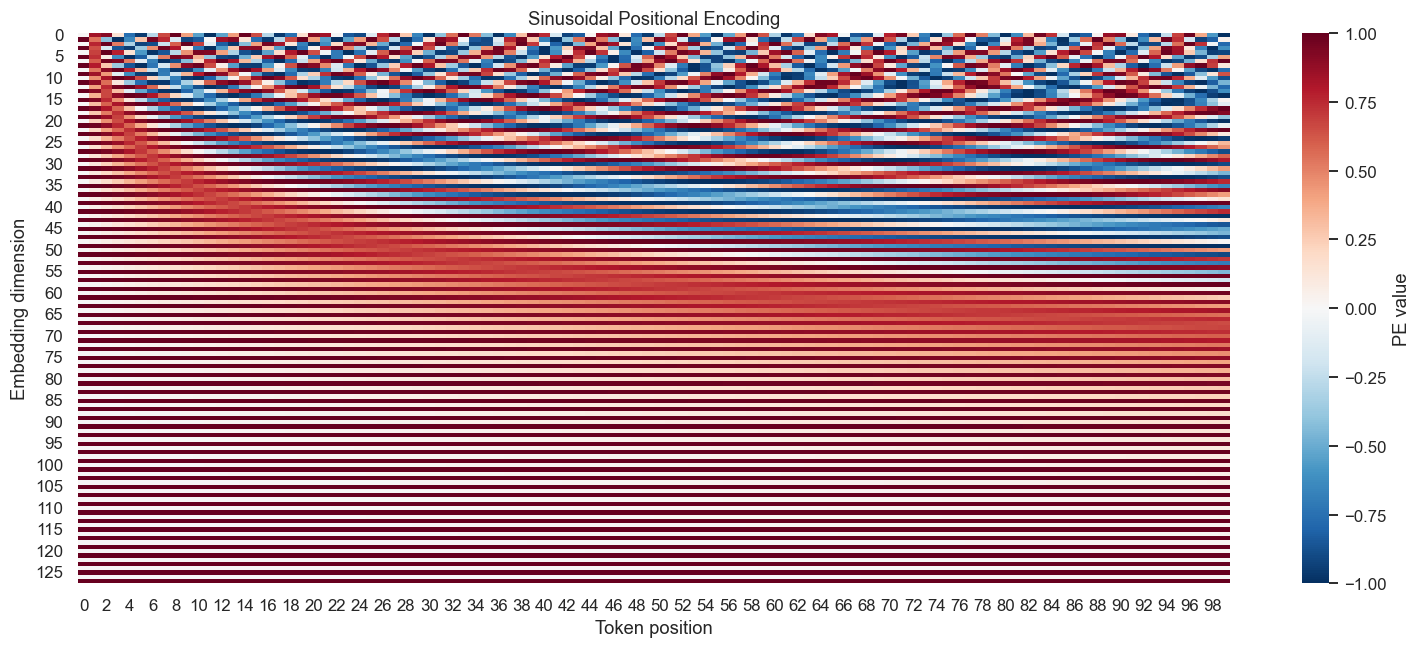

Saved: d:\HUS\NLP\lab7\positional_encoding.png


In [13]:
# Visualize Sinusoidal Positional Encoding
pe = positional_encoding(100, DIM).detach().cpu().numpy()

fig, ax = plt.subplots(figsize=(14, 6))

sns.heatmap(
    pe.T,
    cmap="RdBu_r",
    center=0,
    ax=ax,
    cbar_kws={"label": "PE value"}
)

ax.set_title("Sinusoidal Positional Encoding")
ax.set_xlabel("Token position")
ax.set_ylabel("Embedding dimension")

fig.tight_layout()
fig.savefig(
    LAB_DIR / "positional_encoding.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", LAB_DIR / "positional_encoding.png")

**Nếu chỉ dùng self-attention và không có positional information, tại sao thứ tự trở thành vấn đề?** 

Khi hoán vị token, embedding chỉ đổi thứ tự hàng. Self-attention không causal và không có tín hiệu vị trí cũng chỉ hoán vị output tương ứng: $F(PX)=PF(X)$. Mean pooling hai output đó giống nhau nên classifier không nhận biết khác biệt thứ tự. Khi thêm PE, cùng một từ ở vị trí khác được cộng vector khác; hai ma trận sau khi căn theo token không còn giống nhau. Mục 12 kiểm tra trực tiếp sau attention.

#### 12. Permutation experiment

S1 = **dog bites man**; 

S2 = **man bites dog**. 




In [14]:
torch.manual_seed(SEED)
permutation_attention = MultiHeadSelfAttention(d_model=4, n_heads=1).eval()
dog_bites_man = torch.tensor([[[1., 0., .5, 0.], [0., 1., 0., .5], [.2, 0., 1., 1.]]])
man_bites_dog = dog_bites_man[:, permutation]
permutation_rows = []
with torch.no_grad():
    for use_position in [False, True]:
        position = pe3[None] if use_position else torch.zeros_like(dog_bites_man)
        z1, _ = permutation_attention(dog_bites_man + position)
        z2, _ = permutation_attention(man_bites_dog + position)
        pooled1, pooled2 = z1.mean(1), z2.mean(1)
        permutation_rows.append({'Position': use_position,
                                 'Aligned token max difference': (z1-z2[:,permutation]).abs().max().item(),
                                 'Mean representation L2 difference': torch.linalg.vector_norm(pooled1-pooled2).item()})
        print('With PE' if use_position else 'Without PE')
        display(pd.DataFrame(torch.cat([pooled1, pooled2]).numpy(), index=['dog bites man', 'man bites dog']))
permutation_results = pd.DataFrame(permutation_rows)
display(permutation_results)

Without PE


,0,1,2,3
dog bites man,-0.358774,0.32161,-0.049071,0.620562
man bites dog,-0.358774,0.32161,-0.049071,0.620562


With PE


,0,1,2,3
dog bites man,-0.458073,0.288141,-0.320451,0.812724
man bites dog,-0.459582,0.251316,-0.300776,0.808720


,Position,Aligned token max difference,Mean representation L2 difference
0,False,5.960464e-08,3.725290e-09
1,True,8.758104e-02,4.196943e-02


**Kết quả thực nghiệm:** Không PE, sai khác L2 giữa hai vector mean là **3.725e-09**, ở mức sai số float32. Sau khi căn output theo token, sai khác lớn nhất là 5.960e-08. Có PE, khoảng cách giữa hai vector mean là **0.041969**, nên biểu diễn có thể phân biệt hai thứ tự trong ví dụ này.

Đây là tính **equivariance** ở mức token và **invariance** sau mean pooling khi không có vị trí; không phải output từng vị trí luôn giữ nguyên. Có PE phá vỡ tính bất biến đó trong thí nghiệm, nhưng không chứng minh model đã hiểu ai cắn ai. First-token pooling, causal mask hoặc tín hiệu vị trí khác sẽ thay đổi giả thiết của phép so sánh.

#### 17. Core implementation — Transformer block



In [15]:
import inspect
print(inspect.getsource(MultiHeadSelfAttention))
print(inspect.getsource(TransformerBlock))

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        if n_heads <= 0 or d_model % n_heads:
            raise ValueError('d_model phải chia hết cho n_heads > 0.')
        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        self.wq = nn.Linear(d_model, d_model)
        self.wk = nn.Linear(d_model, d_model)
        self.wv = nn.Linear(d_model, d_model)
        self.wo = nn.Linear(d_model, d_model)

    def forward(self, x, valid=None):
        batch, length, dimension = x.shape
        if valid is None:
            valid = torch.ones(batch, length, dtype=torch.bool, device=x.device)
        if not valid.any(dim=1).all():
            raise ValueError('Mỗi sequence cần ít nhất một token thật.')

        def split_heads(projection):
            return projection(x).reshape(batch, length, self.n_heads, self.d_k).transpose(1, 2)

        q, k, v = [split_heads(layer) for layer in (self.wq, self.wk, self.wv)]
    

#### 18. Kiểm tra shape

 

In [16]:
torch.manual_seed(SEED)
shape_block = TransformerBlock(128, 4, 256).eval()
shape_x = torch.randn(8, 100, 128)
with torch.no_grad():
    q, k, v = [layer(shape_x).reshape(8, 100, 4, 32).transpose(1, 2)
               for layer in [shape_block.attention.wq, shape_block.attention.wk, shape_block.attention.wv]]
    scores = q @ k.transpose(-1, -2) / np.sqrt(32)
    context = scores.softmax(-1) @ v
    attended, _ = shape_block.attention(shape_x)
    residual = shape_block.norm1(shape_x + attended)
    ffn_hidden = shape_block.ffn[0](residual)
    ffn_output = shape_block.ffn(residual)
    shape_output = shape_block(shape_x)
display(pd.DataFrame([(name, tuple(tensor.shape)) for name, tensor in
    [('X', shape_x), ('Q', q), ('K', k), ('V', v), ('Scores', scores),
     ('Context per head', context), ('Attention output', attended),
     ('FFN hidden', ffn_hidden), ('FFN output', ffn_output), ('Output', shape_output)]], columns=['Tensor', 'Shape']))
assert shape_output.shape == shape_x.shape

,Tensor,Shape
0,X,"(8, 100, 128)"
1,Q,"(8, 4, 100, 32)"
2,K,"(8, 4, 100, 32)"
3,V,"(8, 4, 100, 32)"
4,Scores,"(8, 4, 100, 100)"
5,Context per head,"(8, 4, 100, 32)"
6,Attention output,"(8, 100, 128)"
7,FFN hidden,"(8, 100, 256)"
8,FFN output,"(8, 100, 128)"
9,Output,"(8, 100, 128)"


#### 19. Experiment 2 — Number of attention heads
 

In [17]:
def clean_text(text):
    return re.sub(r'\s+', ' ', str(text).replace('<br />', ' ')).strip()

def tokenize(text):
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", clean_text(text).lower().replace('’', "'"))

raw = pd.read_csv(LAB_DIR.parent / 'dataset' / 'IMDB Dataset.csv')
df = pd.DataFrame({'text': raw.review.map(clean_text), 'label': (raw.sentiment == 'positive').astype(int), 'source_row': raw.index})
df = df.drop_duplicates('text').reset_index(drop=True)
idx_train_full, idx_rest = train_test_split(np.arange(len(df)), train_size=.70, random_state=SEED, stratify=df.label)
idx_valid_full, idx_test_full = train_test_split(idx_rest, train_size=.5, random_state=SEED, stratify=df.label.iloc[idx_rest])
subset = np.random.default_rng(SEED).choice(len(idx_train_full), size=10000, replace=False)
idx_train, idx_valid, idx_test = idx_train_full[subset], idx_valid_full[:2000], idx_test_full[:2000]
train_texts, valid_texts, test_texts = [df.text.iloc[idx].tolist() for idx in (idx_train, idx_valid, idx_test)]
y_train, y_valid, y_test = [df.label.iloc[idx].to_numpy() for idx in (idx_train, idx_valid, idx_test)]
train_tokens, valid_tokens, test_tokens = [[tokenize(t) for t in texts] for texts in (train_texts, valid_texts, test_texts)]
counter = Counter(word for tokens in train_tokens for word in tokens)
words = sorted((w for w, count in counter.items() if count >= 2), key=lambda w: (-counter[w], w))
vocab = {'<PAD>': 0, '<UNK>': 1, **{w: i+2 for i, w in enumerate(words)}}
lengths = np.array([len(tokens) for tokens in train_tokens])

def encode_tokens(tokens, max_length):
    ids = [vocab.get(word, 1) for word in tokens[:max_length]] or [1]
    return ids + [0] * (max_length - len(ids))

dataset_cache = {}
def get_datasets(max_length):
    if max_length not in dataset_cache:
        dataset_cache[max_length] = [TensorDataset(torch.tensor([encode_tokens(t, max_length) for t in tokens], dtype=torch.long),
                                                  torch.tensor(labels, dtype=torch.long))
                                     for tokens, labels in [(train_tokens, y_train), (valid_tokens, y_valid), (test_tokens, y_test)]]
    return dataset_cache[max_length]

print(f'Raw={len(raw)}, clean={len(df)}, duplicates={len(raw)-len(df)}, vocabulary={len(vocab)}')
display(pd.DataFrame([{'Split': name, 'Samples': len(y), 'Negative': int((y==0).sum()), 'Positive': int((y==1).sum())}
                     for name, y in [('Train', y_train), ('Validation', y_valid), ('Test', y_test)]]))

Raw=50000, clean=49578, duplicates=422, vocabulary=33514


,Split,Samples,Negative,Positive
0,Train,10000,4981,5019
1,Validation,2000,992,1008
2,Test,2000,999,1001


In [18]:
class TransformerClassifier(nn.Module):
    def __init__(self, n_heads=4, max_length=BASE_LENGTH, pooling='mean'):
        super().__init__()
        if pooling not in ('mean', 'first'):
            raise ValueError('pooling phải là mean hoặc first')
        self.pooling = pooling
        self.max_length = max_length
        self.embedding = nn.Embedding(len(vocab), DIM, padding_idx=0)
        self.register_buffer('position', positional_encoding(max_length, DIM))
        self.block = TransformerBlock(DIM, n_heads, D_FF, dropout=.1)
        self.dropout = nn.Dropout(.3)
        self.classifier = nn.Linear(DIM, 2)

    def forward(self, ids, return_attention=False):
        valid = ids.ne(0)
        x = self.embedding(ids) + self.position[:ids.shape[1]]
        hidden, weights = self.block(x, valid, return_attention=True)
        if self.pooling == 'mean':
            pooled = (hidden * valid[:, :, None]).sum(1) / valid.sum(1, keepdim=True)
        else:
            pooled = hidden[:, 0]  # token thật đầu tiên; mô hình được train với cách lấy này
        logits = self.classifier(self.dropout(pooled))
        return (logits, weights) if return_attention else logits

In [19]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    probabilities, labels, total_loss = [], [], 0.
    for ids, y in loader:
        logits = model(ids.to(DEVICE))
        total_loss += nn.functional.cross_entropy(logits, y.to(DEVICE), reduction='sum').item()
        probabilities.append(logits.softmax(-1)[:, 1].cpu().numpy())
        labels.append(y.numpy())
    y, probabilities = np.concatenate(labels), np.concatenate(probabilities)
    return total_loss / len(y), y, (probabilities >= .5).astype(int), probabilities

runs = {}
def train_run(name, factory, max_length=BASE_LENGTH, heads=None, pooling='last'):
    if name in runs:
        return runs[name]
    torch.manual_seed(SEED)
    model = factory().to(DEVICE)
    train_ds, valid_ds, test_ds = get_datasets(max_length)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=torch.Generator().manual_seed(SEED))
    valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    best_loss, best_epoch, best_state = float('inf'), 0, None
    history = []
    started = time.perf_counter()
    for epoch in range(1, EPOCHS+1):
        model.train()
        loss_sum = 0.
        for ids, y in train_loader:
            ids, y = ids.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(ids), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()
            loss_sum += loss.item() * len(y)
        valid_loss, vy, vp, _ = evaluate(model, valid_loader)
        history.append({'epoch': epoch, 'train_loss': loss_sum / len(train_ds), 'valid_loss': valid_loss,
                        'valid_accuracy': accuracy_score(vy, vp)})
        if valid_loss < best_loss:
            best_loss, best_epoch, best_state = valid_loss, epoch, copy.deepcopy(model.state_dict())
        print(f'{name} | epoch {epoch}/{EPOCHS} | train={history[-1]["train_loss"]:.4f} | valid={valid_loss:.4f}', flush=True)
    elapsed = time.perf_counter() - started
    model.load_state_dict(best_state)
    test_loss, yt, yp, prob = evaluate(model, test_loader)
    row = {'Model': name, 'Heads': heads, 'd_k': DIM // heads if heads else None,
           'Length': max_length, 'Pooling': pooling, 'Parameters': sum(p.numel() for p in model.parameters()),
           'Training time (s)': elapsed, 'Accuracy': accuracy_score(yt, yp),
           'Precision': precision_score(yt, yp, zero_division=0), 'Recall': recall_score(yt, yp, zero_division=0),
           'F1': f1_score(yt, yp, zero_division=0), 'Best epoch': best_epoch}
    runs[name] = {'model': model, 'row': row, 'history': history, 'true': yt, 'pred': yp, 'prob': prob}
    return runs[name]

def transformer_run(heads=4, max_length=BASE_LENGTH, pooling='mean'):
    name = f'Transformer-h{heads}-T{max_length}-{pooling}'
    return train_run(name, lambda: TransformerClassifier(heads, max_length, pooling), max_length, heads, pooling)

In [20]:
head_runs = [transformer_run(heads=h) for h in [1, 2, 4, 8]]
heads_table = pd.DataFrame([run['row'] for run in head_runs])
display(heads_table[['Heads', 'd_k', 'Parameters', 'Training time (s)', 'Accuracy', 'F1']])
base_run = transformer_run(heads=4)
base_model = base_run['model'].eval()

Transformer-h1-T64-mean | epoch 1/5 | train=0.6544 | valid=0.6036
Transformer-h1-T64-mean | epoch 2/5 | train=0.5384 | valid=0.5985
Transformer-h1-T64-mean | epoch 3/5 | train=0.4062 | valid=0.5399
Transformer-h1-T64-mean | epoch 4/5 | train=0.2783 | valid=0.6038
Transformer-h1-T64-mean | epoch 5/5 | train=0.1725 | valid=0.7418
Transformer-h2-T64-mean | epoch 1/5 | train=0.6469 | valid=0.5934
Transformer-h2-T64-mean | epoch 2/5 | train=0.5361 | valid=0.5546
Transformer-h2-T64-mean | epoch 3/5 | train=0.4110 | valid=0.5427
Transformer-h2-T64-mean | epoch 4/5 | train=0.2778 | valid=0.6055
Transformer-h2-T64-mean | epoch 5/5 | train=0.1633 | valid=0.7598
Transformer-h4-T64-mean | epoch 1/5 | train=0.6382 | valid=0.6088
Transformer-h4-T64-mean | epoch 2/5 | train=0.5213 | valid=0.5598
Transformer-h4-T64-mean | epoch 3/5 | train=0.4047 | valid=0.5263
Transformer-h4-T64-mean | epoch 4/5 | train=0.2746 | valid=0.6072
Transformer-h4-T64-mean | epoch 5/5 | train=0.1576 | valid=0.7579
Transforme

,Heads,d_k,Parameters,Training time (s),Accuracy,F1
0,1,128,4422530,47.145420,0.7570,0.758209
1,2,64,4422530,48.489145,0.7475,0.751843
2,4,32,4422530,49.151852,0.7550,0.756703
3,8,16,4422530,52.564599,0.7505,0.747086


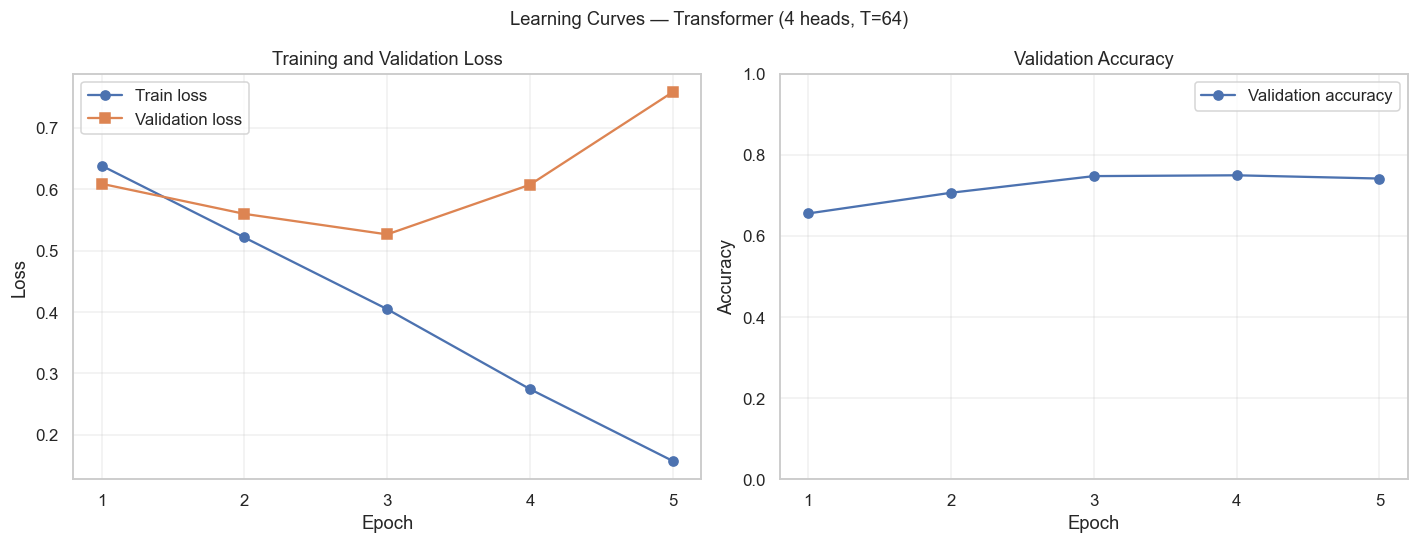

Saved: d:\HUS\NLP\lab7\learning_curves.png


In [21]:
# Visualize Training and Validation Curves
history = base_run["history"]

epochs = [item["epoch"] for item in history]
train_losses = [item["train_loss"] for item in history]
valid_losses = [item["valid_loss"] for item in history]
valid_accuracies = [item["valid_accuracy"] for item in history]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Loss curves
axes[0].plot(
    epochs, train_losses,
    marker="o", label="Train loss"
)
axes[0].plot(
    epochs, valid_losses,
    marker="s", label="Validation loss"
)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(epochs)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Validation accuracy
axes[1].plot(
    epochs, valid_accuracies,
    marker="o", label="Validation accuracy"
)

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(epochs)
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle(
    "Learning Curves — Transformer (4 heads, T=64)"
)

fig.tight_layout()
fig.savefig(
    LAB_DIR / "learning_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", LAB_DIR / "learning_curves.png")

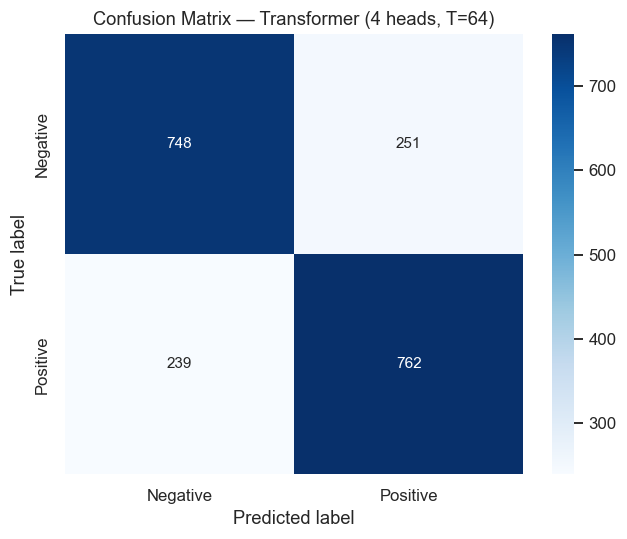

Saved: d:\HUS\NLP\lab7\confusion_matrix.png


In [22]:
# Visualize Confusion Matrix
cm = confusion_matrix(
    base_run["true"],
    base_run["pred"],
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
    ax=ax
)

ax.set_title(
    "Confusion Matrix — Transformer (4 heads, T=64)"
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

fig.tight_layout()
fig.savefig(
    LAB_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", LAB_DIR / "confusion_matrix.png")

**Tăng số heads có đồng nghĩa với tăng representation dimension không?** Không. Tổng chiều output vẫn là **128**. Với h = 1, 2, 4, 8 thì d_k = 128, 64, 32, 16; tăng gấp đôi h làm d_k giảm một nửa.

| Heads | d_k | Parameters | Training time (s) | Accuracy | F1 |
| --- | --- | --- | --- | --- | --- |
| 1 | 128 | 4422530 | 40.6458 | 0.7570 | 0.7582 |
| 2 | 64 | 4422530 | 42.0451 | 0.7475 | 0.7518 |
| 4 | 32 | 4422530 | 48.2187 | 0.7550 | 0.7567 |
| 8 | 16 | 4422530 | 52.7197 | 0.7505 | 0.7471 |

Số tham số của bốn mô hình bằng nhau (**4,422,530**) vì các phép chiếu Q/K/V/O vẫn ánh xạ 128 → 128, chỉ thay cách chia các chiều thành head; embedding và FFN cũng giữ nguyên. Điều này không có nghĩa bộ nhớ attention bằng nhau: số ma trận T × T tăng theo h.

Accuracy không tăng đơn điệu theo số head trong lần chạy này. Không chọn số head dựa trên test để tiếp tục application; cấu hình 4 heads đã được cố định trước các thí nghiệm.

#### 20. Experiment 3 — Attention head diversity

 

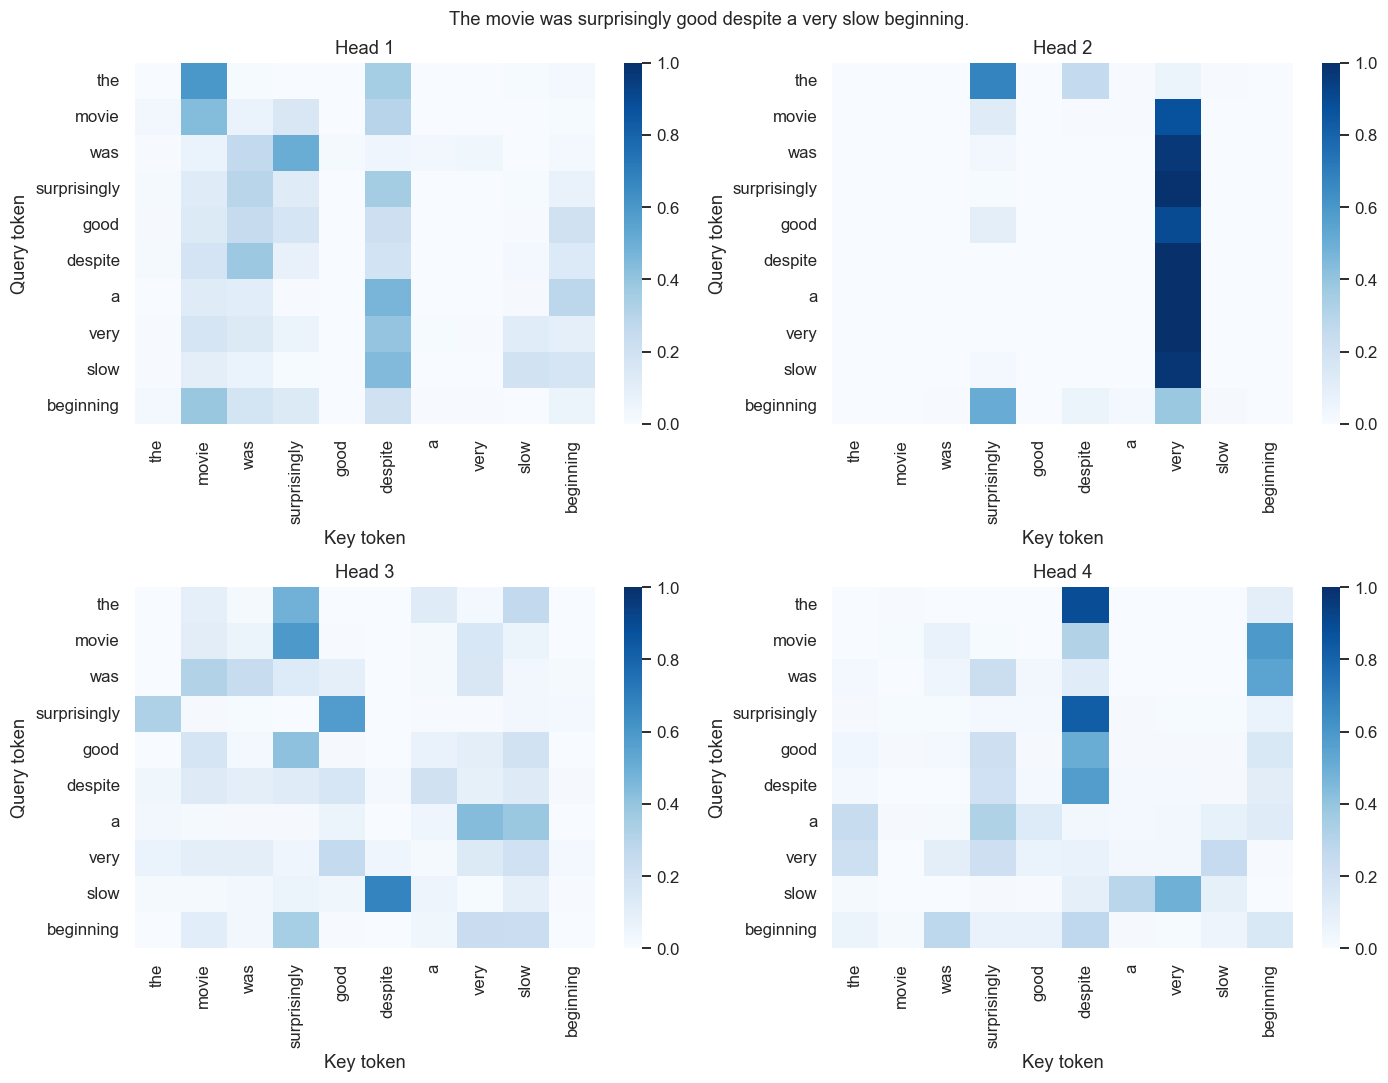

,Head,Normalized entropy,Mean row maximum,Top received token
0,1,0.636809,0.423077,despite
1,2,0.129825,0.888790,very
2,3,0.667114,0.430208,surprisingly
3,4,0.573771,0.527312,despite


,1,2,3,4
1,0.000000,0.183775,0.136007,0.119860
2,0.183775,0.000000,0.149433,0.175666
3,0.136007,0.149433,0.000000,0.152620
4,0.119860,0.175666,0.152620,0.000000


In [23]:
@torch.no_grad()
def inspect_text(text, model=base_model):
    model.eval()
    tokens = tokenize(text)[:model.max_length] or ['<UNK>']
    ids = torch.tensor([encode_tokens(tokens, model.max_length)], dtype=torch.long, device=DEVICE)
    logits, weights = model(ids, return_attention=True)
    return tokens, float(logits.softmax(-1)[0, 1]), weights[0, :, :len(tokens), :len(tokens)].cpu().numpy()

head_sentence = 'The movie was surprisingly good despite a very slow beginning.'
head_tokens, head_probability, head_weights = inspect_text(head_sentence)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
head_statistics = []
for i, ax in enumerate(axes.flat):
    weights = head_weights[i]
    sns.heatmap(weights, ax=ax, xticklabels=head_tokens, yticklabels=head_tokens, cmap='Blues', vmin=0, vmax=1)
    ax.set(title=f'Head {i+1}', xlabel='Key token', ylabel='Query token')
    entropy = -(weights * np.log(np.maximum(weights, 1e-12))).sum(-1).mean() / np.log(len(head_tokens))
    head_statistics.append({'Head': i+1, 'Normalized entropy': float(entropy),
                            'Mean row maximum': float(weights.max(-1).mean()),
                            'Top received token': head_tokens[int(weights.mean(0).argmax())]})
fig.suptitle(head_sentence)
plt.tight_layout()
fig.savefig(LAB_DIR / 'attention_heads.png', dpi=160, bbox_inches='tight')
plt.show()
head_stats_table = pd.DataFrame(head_statistics)
head_distances = np.array([[np.abs(a-b).mean() for b in head_weights] for a in head_weights])
display(head_stats_table)
display(pd.DataFrame(head_distances, index=range(1, 5), columns=range(1, 5)))

**Multi-head có tạo pattern khác nhau trong experiment này không?** Có. Sai khác tuyệt đối trung bình giữa các cặp head nằm trong khoảng **0.1199–0.1838** trên câu đã chọn.

- **Head 2 tập trung nhất** theo entropy chuẩn hóa (0.1298); key nhận attention trung bình cao nhất là `very`.
- **Head 3 phân tán nhất** trong bốn head theo entropy (0.6671); key nhận attention trung bình cao nhất là `surprisingly`. “Phân tán nhất” ở đây chỉ là so sánh tương đối.
- Hai head gần nhau nhất là **1 và 4** (sai khác trung bình 0.1199); xa nhau nhất là **1 và 2** (0.1838).

Không có hai ma trận trùng hẳn trên câu này. Chưa đủ bằng chứng kết luận head nào dư thừa: pattern gần nhau trên một câu không chứng minh có thể bỏ head mà không đổi dự đoán. Không gán head là “syntax” hay “semantics”; attention heatmap chỉ thể hiện trọng số.

#### 21. Experiment 4 — Transformer vs RNN/LSTM

 

In [ ]:
class LSTMClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab), DIM, padding_idx=0)
        self.lstm = nn.LSTM(DIM, DIM, batch_first=True)
        self.dropout = nn.Dropout(.3)
        self.classifier = nn.Linear(DIM, 2)

    def forward(self, ids):
        lengths = ids.ne(0).sum(1)
        hidden, _ = self.lstm(self.embedding(ids))
        last = hidden[torch.arange(len(ids), device=ids.device), lengths-1]
        return self.classifier(self.dropout(last))

lstm_run = train_run('LSTM', LSTMClassifier)
comparison_table = pd.DataFrame([lstm_run['row'], base_run['row']])
display(comparison_table[['Model', 'Parameters', 'Training time (s)', 'Accuracy', 'Precision', 'Recall', 'F1']])

LSTM | epoch 1/5 | train=0.6900 | valid=0.6790
LSTM | epoch 2/5 | train=0.6115 | valid=0.6568
LSTM | epoch 3/5 | train=0.5000 | valid=0.6081
LSTM | epoch 4/5 | train=0.3407 | valid=0.6458
LSTM | epoch 5/5 | train=0.2058 | valid=0.7364


,Model,Parameters,Training time (s),Accuracy,Precision,Recall,F1
0,LSTM,4422146,27.886580,0.7145,0.699443,0.753247,0.725349
1,Transformer-h4-T64-mean,4422530,48.218693,0.7550,0.752221,0.761239,0.756703


| Model | Parameters | Training time (s) | Accuracy | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| LSTM | 4422146 | 27.8866 | 0.7145 | 0.6994 | 0.7532 | 0.7253 |
| Transformer (4 heads, mean) | 4422530 | 48.2187 | 0.7550 | 0.7522 | 0.7612 | 0.7567 |

**Sự khác biệt performance có thể xuất phát từ những thành phần architecture nào?** LSTM nén chuỗi vào state ở token cuối, trong khi Transformer cho mỗi token tương tác trực tiếp với các token khác rồi lấy mean toàn chuỗi. Multi-head, PE, FFN phi tuyến, residual và LayerNorm cũng thay đổi cách tạo và tối ưu representation. Những thành phần này thay đổi đồng thời, nên không thể quy toàn bộ chênh lệch cho riêng attention hay riêng PE.

Transformer có F1 **0.7567**, LSTM **0.7253**; thời gian tương ứng **48.22s** và **27.89s**. Kết quả chỉ áp dụng cho cấu hình, CPU và seed đã nêu. Cùng giới hạn 64 token làm cả hai mất phần đuôi review dài; Transformer không mặc nhiên thắng hoặc nhanh hơn trong mọi điều kiện.

#### 22. Experiment 5 — Sequence length

 

In [ ]:
length_rows = []
for max_length in [32, 64, 128, 256]:
    run = transformer_run(max_length=max_length)
    length_rows.append({'Length': max_length,
                        'Tokens retained': np.minimum(lengths, max_length).sum() / lengths.sum(),
                        'Attention elements/head': max_length**2,
                        'Attention memory (MiB)': 4 * BATCH_SIZE * 4 * max_length**2 / 2**20,
                        'Training time (s)': run['row']['Training time (s)'], 'F1': run['row']['F1']})
length_table = pd.DataFrame(length_rows)
display(length_table)

Transformer-h4-T32-mean | epoch 1/5 | train=0.6557 | valid=0.6065
Transformer-h4-T32-mean | epoch 2/5 | train=0.5645 | valid=0.5985
Transformer-h4-T32-mean | epoch 3/5 | train=0.4670 | valid=0.5900
Transformer-h4-T32-mean | epoch 4/5 | train=0.3513 | valid=0.6876
Transformer-h4-T32-mean | epoch 5/5 | train=0.2347 | valid=0.8985
Transformer-h4-T128-mean | epoch 1/5 | train=0.6039 | valid=0.5100
Transformer-h4-T128-mean | epoch 2/5 | train=0.4500 | valid=0.4437
Transformer-h4-T128-mean | epoch 3/5 | train=0.3176 | valid=0.4220
Transformer-h4-T128-mean | epoch 4/5 | train=0.1949 | valid=0.5019
Transformer-h4-T128-mean | epoch 5/5 | train=0.0878 | valid=0.7673
Transformer-h4-T256-mean | epoch 1/5 | train=0.5764 | valid=0.4906
Transformer-h4-T256-mean | epoch 2/5 | train=0.3930 | valid=0.3668
Transformer-h4-T256-mean | epoch 3/5 | train=0.2532 | valid=0.3608
Transformer-h4-T256-mean | epoch 4/5 | train=0.1324 | valid=0.5045
Transformer-h4-T256-mean | epoch 5/5 | train=0.0605 | valid=0.6389


,Length,Tokens retained,Attention elements/head,Attention memory (MiB),Training time (s),F1
0,32,0.139380,1024,1.0,29.660765,0.716628
1,64,0.275618,4096,4.0,48.218693,0.756703
2,128,0.518261,16384,16.0,103.243524,0.812314
3,256,0.771938,65536,64.0,226.771664,0.819466


| Length | Tokens retained | Attention memory (MiB) | Training time (s) | F1 |
| --- | --- | --- | --- | --- |
| 32 | 0.1394 | 1.0000 | 29.6608 | 0.7166 |
| 64 | 0.2756 | 4.0000 | 48.2187 | 0.7567 |
| 128 | 0.5183 | 16.0000 | 103.2435 | 0.8123 |
| 256 | 0.7719 | 64.0000 | 226.7717 | 0.8195 |

**Tại sao không đơn giản tăng sequence length để giải quyết mọi vấn đề?** Tăng từ 128 lên 256 làm số phần tử attention mỗi head tăng từ **16.384 lên 65.536 (4 lần)**. Với batch 64, 4 heads, một tensor float32 tăng từ **16 MiB lên 64 MiB**; training còn cần nhiều tensor khác. Thời gian thực không nhất thiết tăng đúng 4 lần vì còn embedding, projections, FFN và optimizer.

Tỷ lệ giữ token tăng từ **13.94%** ở T=32 lên **77.19%** ở T=256. F1 lần lượt là **0.7166, 0.7567, 0.8123, 0.8195**. Thêm context có thể giúp, nhưng cũng tăng chi phí và đưa thêm thông tin không liên quan. T=256 vẫn cắt các review dài hơn 256 token; chỉ tăng T không tự giải quyết phủ định, nhập nhằng hoặc thiếu dữ liệu học.

#### 23. Application — Transformer text classification

`Raw text → Tokenizer → IDs → Embedding + PE → Transformer block → Masked mean pooling → Linear → Softmax → Prediction`.

Dùng tiếp Transformer 4 heads, T=64 ở mục 19; không chọn model theo test. Thử năm loại câu theo đề. Nhãn kỳ vọng do người viết đặt để diễn giải các ví dụ, không phải gold label của IMDb; câu ambiguous không gán một nhãn đúng duy nhất. P(predicted) là xác suất softmax của nhãn dự đoán, chưa được hiệu chỉnh độ tin cậy.

In [ ]:
application_cases = [
    ('Short', 'I really enjoyed this movie.', 'positive'),
    ('Long', 'I watched this movie with my family on a quiet evening, expecting a familiar story and little more. '
     'The opening takes its time to introduce the town, the neighbors, and the problems that bring everyone together. '
     'Several scenes follow ordinary conversations at home, at work, and during a long journey. '
     'Although the pace is slow and some scenes repeat information, the performances feel sincere, '
     'the characters become more interesting, and the ending rewards the time spent with them. '
     'I left feeling moved and would gladly recommend it.', 'positive'),
    ('Negation', 'I did not enjoy this movie at all.', 'negative'),
    ('Contrast', 'The beginning was boring, but the ending was excellent and I loved the movie overall.', 'positive'),
    ('Ambiguous', 'The movie was neither particularly good nor particularly bad; some moments worked and others did not.', 'ambiguous'),
]
application_rows = []
for category, text, expected in application_cases:
    tokens, probability, weights = inspect_text(text)
    predicted = 'positive' if probability >= .5 else 'negative'
    application_rows.append({'Type': category, 'Text': text, 'Expected': expected, 'Predicted': predicted,
                             'P(positive)': probability, 'P(predicted)': max(probability, 1-probability),
                             'Original tokens': len(tokenize(text)), 'Seen tokens': len(tokens)})
application_table = pd.DataFrame(application_rows)
display(application_table.drop(columns='Text'))
for row in application_rows:
    print(f"{row['Type']}: {row['Text']}\n  {row['Predicted']} | P(predicted)={row['P(predicted)']:.4f}")

Short: I really enjoyed this movie.
  positive | P(predicted)=0.6806
Long: I watched this movie with my family on a quiet evening, expecting a familiar story and little more. The opening takes its time to introduce the town, the neighbors, and the problems that bring everyone together. Several scenes follow ordinary conversations at home, at work, and during a long journey. Although the pace is slow and some scenes repeat information, the performances feel sincere, the characters become more interesting, and the ending rewards the time spent with them. I left feeling moved and would gladly recommend it.
  positive | P(predicted)=0.9858
Negation: I did not enjoy this movie at all.
  negative | P(predicted)=0.8420
Contrast: The beginning was boring, but the ending was excellent and I loved the movie overall.
  negative | P(predicted)=0.8892
Ambiguous: The movie was neither particularly good nor particularly bad; some moments worked and others did not.
  negative | P(predicted)=0.9898


,Type,Expected,Predicted,P(positive),P(predicted),Original tokens,Seen tokens
0,Short,positive,positive,0.680623,0.680623,5,5
1,Long,positive,positive,0.985841,0.985841,87,64
2,Negation,negative,negative,0.157959,0.842041,8,8
3,Contrast,positive,negative,0.110832,0.889168,15,15
4,Ambiguous,ambiguous,negative,0.010240,0.989760,16,16


| Loại | Kỳ vọng | Dự đoán | P(positive) | Token gốc → thấy |
| --- | --- | --- | --- | --- |
| Short | positive | positive | 0.6806 | 5 → 5 |
| Long | positive | positive | 0.9858 | 87 → 64 |
| Negation | negative | negative | 0.1580 | 8 → 8 |
| Contrast | positive | negative | 0.1108 | 15 → 15 |
| Ambiguous | ambiguous | negative | 0.0102 | 16 → 16 |

Model khớp nhãn kỳ vọng ở **3/4** ví dụ có sentiment định hướng rõ; đây chỉ là nhóm câu minh họa, không phải accuracy trên test. Với negation cần xét phạm vi của “not”; với contrast cần phân biệt đánh giá phần đầu và đánh giá tổng thể, không chỉ tìm từ tích cực/tiêu cực.

Câu dài có **87** token nhưng model chỉ thấy **64**; phần kết luận cuối bị cắt có thể làm mất bằng chứng sentiment. Câu ambiguous chứa đánh giá lẫn lộn, trong khi classifier bắt buộc chọn một trong hai lớp; không coi lựa chọn đó là chắc chắn đúng/sai. Xác suất softmax cao cũng không tự chứng minh dự đoán đáng tin cậy.

#### 25. Experiment 6 — Pooling strategy

 

In [ ]:
first_run = transformer_run(pooling='first')
pooling_table = pd.DataFrame([base_run['row'], first_run['row']])
display(pooling_table[['Pooling', 'Accuracy', 'F1', 'Training time (s)']])

Transformer-h4-T64-first | epoch 1/5 | train=0.6727 | valid=0.6267
Transformer-h4-T64-first | epoch 2/5 | train=0.5993 | valid=0.6114
Transformer-h4-T64-first | epoch 3/5 | train=0.5411 | valid=0.6404
Transformer-h4-T64-first | epoch 4/5 | train=0.4630 | valid=0.6534
Transformer-h4-T64-first | epoch 5/5 | train=0.3717 | valid=0.8393


,Pooling,Accuracy,F1,Training time (s)
0,mean,0.755,0.756703,48.218693
1,first,0.646,0.599548,43.146701


| Pooling | Accuracy | F1 | Training time (s) |
| --- | --- | --- | --- |
| Mean | 0.7550 | 0.7567 | 48.2187 |
| First-token / CLS-style | 0.6460 | 0.5995 | 43.1467 |

**Cách lấy sequence representation có ảnh hưởng classification không?** Có trong lần chạy này: accuracy chênh **0.1090**, F1 chênh **0.1572**. Mean lấy thông tin từ tất cả vị trí thật; first-token buộc representation ở vị trí đầu mang thông tin cho classifier. Cả hai nhận gradient khác nhau qua pooling, nên quá trình học cũng khác.

Không suy rộng rằng một cách luôn tốt hơn. First-token ở đây là token thật đầu câu được contextualize, không phải [CLS] đã pretrained; không dùng kết quả này để đánh giá pooling của BERT.

#### 26. Error analysis
 

In [24]:
rng_errors = np.random.default_rng(SEED)
correct_indices = rng_errors.choice(np.flatnonzero(base_run['pred'] == y_test), 3, replace=False)
incorrect_indices = rng_errors.choice(np.flatnonzero(base_run['pred'] != y_test), 3, replace=False)
error_examples = []
for group, indices in [('C', correct_indices), ('E', incorrect_indices)]:
    for number, index in enumerate(indices, 1):
        index = int(index)
        tokens, probability, weights = inspect_text(test_texts[index])
        received = weights.mean(axis=(0, 1))
        top = np.argsort(-received, kind='stable')[:5]
        example = {'ID': f'{group}{number}', 'test_index': index, 'source_row': int(df.iloc[idx_test[index]].source_row),
                   'True': int(y_test[index]), 'Predicted': int(base_run['pred'][index]), 'P(positive)': probability,
                   'Original tokens': len(test_tokens[index]), 'Seen tokens': len(tokens),
                   'UNK': sum(word not in vocab for word in tokens),
                   'Top attention': [(tokens[j], int(j), float(received[j])) for j in top],
                   'Top per head': [[(tokens[j], int(j), float(head.mean(0)[j]))
                                     for j in np.argsort(-head.mean(0), kind='stable')[:3]] for head in weights],
                   'Seen text': ' '.join(tokens), 'Full text': test_texts[index]}
        error_examples.append(example)
display(pd.DataFrame(error_examples)[['ID', 'test_index', 'source_row', 'True', 'Predicted', 'P(positive)', 'Original tokens', 'Seen tokens', 'UNK', 'Top attention']])
for example in error_examples:
    print(example['ID'], '| model sees:', example['Seen text'])
    print('Top keys per head:', example['Top per head'])

,ID,test_index,source_row,True,Predicted,P(positive),Original tokens,Seen tokens,UNK,Top attention
0,C1,1317,28627,1,1,0.823228,177,64,2,"[(100, 50, 0.3618239164352417), (things, 7, 0...."
1,C2,171,3174,0,0,0.207422,211,64,0,"[(cheap, 47, 0.2142452597618103), (poorly, 60,..."
2,C3,1544,44526,0,0,0.011628,639,64,1,"[(worst, 5, 0.2741403877735138), (disappointin..."
3,E1,193,15212,1,0,0.179555,447,64,0,"[(shallow, 1, 0.21739564836025238), (looks, 32..."
4,E2,1400,48743,1,0,0.384004,202,64,0,"[(zero, 2, 0.19557881355285645), (stop, 19, 0...."
5,E3,1712,17315,1,0,0.146738,138,64,0,"[(bad, 56, 0.2194392830133438), (obviously, 15..."


C1 | model sees: wracked with guilt after a lot of things felt apart on that ledge an ace mountain rescue climber gabriel walker stallone comes back for his girlfriend jessie janine turner while over the cloudy skies where the weather looks a bit threatening a spectacularly precarious mid air hijacking goes wrong and 100 million taken from a treasury department plane get lost in the middle of
Top keys per head: [[('100', 50, 0.5623048543930054), ('looks', 37, 0.09200017154216766), ('over', 30, 0.07313401997089386)], [('100', 50, 0.8650153279304504), ('precarious', 43, 0.029918164014816284), ('things', 7, 0.024397777393460274)], [('things', 7, 0.5737679600715637), ('hijacking', 46, 0.11987411975860596), ('walker', 19, 0.034739311784505844)], [('guilt', 2, 0.14403682947158813), ('and', 49, 0.10057833045721054), ('wrong', 48, 0.10055220872163773)]]
C2 | model sees: i found the movie at my local video store and i was surprised to see it on dvd i had heard about the explicit sex scenes grue

#### 27. So sánh toàn bộ LAB 04 → LAB 07

| Property | TF-IDF | Avg Word2Vec | LSTM | Attention | Transformer |
|---|---|---|---|---|---|
| Sparse / Dense | Sparse | Dense | Dense | Dense | Dense |
| Word order | Unigram không; n-gram chỉ cục bộ | Không sau average | Có nhờ recurrence | Cần tín hiệu vị trí | Cần tín hiệu vị trí |
| Context-dependent | Không ở mức vector token | Word vector tĩnh | Có | Có | Có |
| Direct token interaction | Không | Không | Qua các state trung gian | Có | Có |
| Sequential computation theo token | Không | Không | Có | Không với encoder | Không với encoder |
| Parallelizable theo token | Có | Có | Hạn chế | Có | Có |
| Long-range interaction | Hạn chế | Không mô hình hóa quan hệ | Khó khi rất xa | Đường tương tác trực tiếp | Đường tương tác trực tiếp |
| Attention | Không | Không | Không ở baseline | Có | Có, nhiều head |
| Positional information | N-gram giữ thứ tự cục bộ | Mất khi average | Ngầm qua thứ tự xử lý | Phải bổ sung | Phải bổ sung |
| Cost theo T, cố định chiều | Gần tuyến tính khi vector hóa | O(T) | O(T), tuần tự | O(T²) attention | O(T²) attention + O(T) FFN |



### Tổng hợp kết quả

`results.csv` lưu một dòng cho mỗi cấu hình đã chạy; các bảng ở mục 19, 21, 22 và 25 dùng lại những dòng tương ứng. Không train lặp cấu hình nền để tạo bảng mới.

In [ ]:
result_rows = []
for run in runs.values():
    row = run['row'].copy()
    length = row['Length']
    row.update({'Tokens retained': np.minimum(lengths, length).sum() / lengths.sum(),
                'Attention memory (MiB)': 4 * BATCH_SIZE * row['Heads'] * length**2 / 2**20 if row['Heads'] else 0.,
                'Seed': SEED, 'd_model': DIM, 'd_ff': D_FF if row['Heads'] else None,
                'Batch size': BATCH_SIZE, 'Epochs': EPOCHS, 'Learning rate': LR,
                'Train samples': len(y_train), 'Validation samples': len(y_valid), 'Test samples': len(y_test)})
    result_rows.append(row)
results = pd.DataFrame(result_rows)
results.to_csv(LAB_DIR / 'results.csv', index=False)
display(results)

,Model,Heads,d_k,Length,Pooling,Parameters,Training time (s),Accuracy,Precision,Recall,F1,Best epoch,Tokens retained,Attention memory (MiB),Seed,d_model,d_ff,Batch size,Epochs,Learning rate,Train samples,Validation samples,Test samples
0,Transformer-h1-T64-mean,1.0,128.0,64,mean,4422530,40.645846,0.7570,0.755203,0.761239,0.758209,3,0.275618,1.0,42,128,256.0,64,5,0.002,10000,2000,2000
1,Transformer-h2-T64-mean,2.0,64.0,64,mean,4422530,42.045115,0.7475,0.739845,0.764236,0.751843,3,0.275618,2.0,42,128,256.0,64,5,0.002,10000,2000,2000
2,Transformer-h4-T64-mean,4.0,32.0,64,mean,4422530,48.218693,0.7550,0.752221,0.761239,0.756703,3,0.275618,4.0,42,128,256.0,64,5,0.002,10000,2000,2000
3,Transformer-h8-T64-mean,8.0,16.0,64,mean,4422530,52.719652,0.7505,0.758230,0.736264,0.747086,3,0.275618,8.0,42,128,256.0,64,5,0.002,10000,2000,2000
4,LSTM,NaN,NaN,64,last,4422146,27.886580,0.7145,0.699443,0.753247,0.725349,3,0.275618,0.0,42,128,NaN,64,5,0.002,10000,2000,2000
5,Transformer-h4-T32-mean,4.0,32.0,32,mean,4422530,29.660765,0.6975,0.674603,0.764236,0.716628,3,0.139380,1.0,42,128,256.0,64,5,0.002,10000,2000,2000
6,Transformer-h4-T128-mean,4.0,32.0,128,mean,4422530,103.243524,0.8110,0.807502,0.817183,0.812314,3,0.518261,16.0,42,128,256.0,64,5,0.002,10000,2000,2000
7,Transformer-h4-T256-mean,4.0,32.0,256,mean,4422530,226.771664,0.8275,0.860440,0.782218,0.819466,3,0.771938,64.0,42,128,256.0,64,5,0.002,10000,2000,2000
8,Transformer-h4-T64-first,4.0,32.0,64,first,4422530,43.146701,0.6460,0.691004,0.529471,0.599548,2,0.275618,4.0,42,128,256.0,64,5,0.002,10000,2000,2000
